# 02 — Davis GCN + CNN Baseline

This notebook trains the baseline drug–target affinity model.

The model uses:

- GCN for drug molecular graphs
- CNN for protein sequences
- Davis binding-affinity data
- Random train, validation and test splitting

In [1]:
from pathlib import Path
import sys

import pandas as pd
import torch
from IPython.display import display
from torch_geometric.loader import DataLoader

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import (
    RANDOM_SEED,
    BATCH_SIZE,
    NUM_WORKERS,
    PROCESSED_DATA_DIR,
    SPLITS_DIR,
)

from src.preprocessing import (
    build_drug_graph_cache,
    build_protein_tensor_cache,
)

from src.dataset import DTADataset

from src.splits import (
    create_random_split,
    validate_split_integrity,
    save_splits,
)

from src.utils import (
    set_random_seed,
    get_device,
)

set_random_seed()

device = get_device()

print("Device:", device)
print("Project root:", PROJECT_ROOT)

Device: mps
Project root: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing


# Load processed Davis data

In [2]:
davis_path = (
    PROCESSED_DATA_DIR
    / "davis_pairs.csv"
)

davis_df = pd.read_csv(davis_path)

print("Davis shape:", davis_df.shape)
print("Unique drugs:", davis_df["drug_id"].nunique())
print("Unique targets:", davis_df["target_id"].nunique())

display(davis_df.head())

Davis shape: (30056, 8)
Unique drugs: 68
Unique targets: 442


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type
0,davis,11314340,AAK1,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQV...,43.0,7.366532,pKd
1,davis,11314340,ABL1(E255K),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd
2,davis,11314340,ABL1(F317I),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd
3,davis,11314340,ABL1(F317I)p,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd
4,davis,11314340,ABL1(F317L),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd


## Create the random split

The Davis drug–target pairs are divided into:

- 70% training
- 15% validation
- 15% testing

The same random seed will be used for every model comparison.

# Create random train, validation and test sets

In [3]:
train_df, validation_df, test_df = create_random_split(
    dataframe=davis_df,
    random_seed=RANDOM_SEED,
)

print("Training rows:", len(train_df))
print("Validation rows:", len(validation_df))
print("Test rows:", len(test_df))
print("Total rows:", len(train_df) + len(validation_df) + len(test_df))

Training rows: 21039
Validation rows: 4508
Test rows: 4509
Total rows: 30056


# Validate the split

In [4]:
split_report = validate_split_integrity(
    train_dataframe=train_df,
    validation_dataframe=validation_df,
    test_dataframe=test_df,
    split_type="random",
)

display(
    pd.DataFrame([split_report])
)

,train_rows,validation_rows,test_rows,pair_overlap,drug_overlap,target_overlap
0,21039,4508,4509,False,True,True


# Save the random split

In [5]:
random_split_directory = (
    SPLITS_DIR
    / "random"
)

save_splits(
    train_dataframe=train_df,
    validation_dataframe=validation_df,
    test_dataframe=test_df,
    output_directory=random_split_directory,
    dataset_name="davis",
)

print("Random Davis split saved to:")
print(random_split_directory)

Random Davis split saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/processed/splits/random


## Prepare drug graphs and protein tensors

Each unique drug is converted into a molecular graph.

Each unique protein sequence is converted into a fixed-length tensor.

These features are created once and reused across the training, validation and test sets.

# Create feature caches

In [6]:
drug_graph_cache = build_drug_graph_cache(
    davis_df
)

protein_tensor_cache = build_protein_tensor_cache(
    davis_df
)

print("Drug graphs:", len(drug_graph_cache))
print("Protein tensors:", len(protein_tensor_cache))

Drug graphs: 68
Protein tensors: 442


## Create PyTorch Geometric datasets

Each sample contains:

- a drug molecular graph;
- a protein sequence tensor;
- one binding-affinity value.

# Create train, validation and test datasets

In [7]:
train_dataset = DTADataset(
    dataframe=train_df,
    drug_graph_cache=drug_graph_cache,
    protein_tensor_cache=protein_tensor_cache,
)

validation_dataset = DTADataset(
    dataframe=validation_df,
    drug_graph_cache=drug_graph_cache,
    protein_tensor_cache=protein_tensor_cache,
)

test_dataset = DTADataset(
    dataframe=test_df,
    drug_graph_cache=drug_graph_cache,
    protein_tensor_cache=protein_tensor_cache,
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(validation_dataset))
print("Test samples:", len(test_dataset))

Training samples: 21039
Validation samples: 4508
Test samples: 4509


In [8]:
sample = train_dataset[0]

print("Drug node shape:", sample.x.shape)
print("Drug edge shape:", sample.edge_index.shape)
print("Protein tensor shape:", sample.target.shape)
print("Affinity shape:", sample.y.shape)
print("Affinity value:", sample.y.item())

Drug node shape: torch.Size([32, 6])
Drug edge shape: torch.Size([2, 70])
Protein tensor shape: torch.Size([1, 1000])
Affinity shape: torch.Size([1])
Affinity value: 5.0


# Create DataLoaders

In [9]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))

Batch size: 32
Training batches: 658
Validation batches: 141
Test batches: 141


In [10]:
batch = next(iter(train_loader))

print("Number of graphs:", batch.num_graphs)
print("Combined node shape:", batch.x.shape)
print("Combined edge shape:", batch.edge_index.shape)
print("Protein batch shape:", batch.target.shape)
print("Affinity batch shape:", batch.y.shape)
print("Batch assignment shape:", batch.batch.shape)

Number of graphs: 32
Combined node shape: torch.Size([1026, 6])
Combined edge shape: torch.Size([2, 2258])
Protein batch shape: torch.Size([32, 1000])
Affinity batch shape: torch.Size([32])
Batch assignment shape: torch.Size([1026])


# Confirm the DataLoaders

In [11]:
assert batch.num_graphs <= BATCH_SIZE
assert batch.x.shape[1] == 6
assert batch.target.shape[1] == 1000
assert batch.y.shape[0] == batch.num_graphs

print("Davis datasets and DataLoaders are ready.")

Davis datasets and DataLoaders are ready.


## Create the GCN + CNN baseline model

The baseline model uses:

- GCN layers to encode drug molecular graphs
- CNN layers to encode protein sequences
- fully connected layers to predict binding affinity

# Import and create the model

In [12]:
from src.models import create_dta_model
from src.utils import count_trainable_parameters

gcn_model = create_dta_model(
    model_name="gcn"
)

gcn_model = gcn_model.to(device)

print("Model created successfully.")
print("Device:", device)

Model created successfully.
Device: mps


In [13]:
print(gcn_model)

DTAModel(
  (drug_encoder): DrugGCNEncoder(
    (conv1): GCNConv(6, 128)
    (conv2): GCNConv(128, 128)
    (conv3): GCNConv(128, 128)
  )
  (protein_encoder): ProteinCNNEncoder(
    (embedding): Embedding(21, 128, padding_idx=0)
    (conv1): Conv1d(128, 128, kernel_size=(7,), stride=(1,), padding=(3,))
    (conv2): Conv1d(128, 128, kernel_size=(7,), stride=(1,), padding=(3,))
    (pool): AdaptiveMaxPool1d(output_size=1)
  )
  (fusion): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)


# Count model parameters

In [14]:
parameter_count = count_trainable_parameters(
    gcn_model
)

print(
    "Trainable parameters:",
    f"{parameter_count:,}"
)

Trainable parameters: 299,265


# Test one forward pass

In [15]:
example_batch = next(
    iter(train_loader)
)

example_batch = example_batch.to(device)

gcn_model.eval()

with torch.no_grad():
    example_predictions = gcn_model(
        example_batch
    )

print(
    "Prediction shape:",
    example_predictions.shape
)

print(
    "True affinity shape:",
    example_batch.y.shape
)

print(
    "First five predictions:",
    example_predictions[:5]
    .detach()
    .cpu()
    .tolist()
)

Prediction shape: torch.Size([32])
True affinity shape: torch.Size([32])
First five predictions: [0.253542959690094, 0.2407003790140152, 0.24267074465751648, 0.23782871663570404, 0.2612743377685547]


# Confirm the model works

In [16]:
assert example_predictions.shape[0] == (
    example_batch.num_graphs
)

assert torch.isfinite(
    example_predictions
).all()

print(
    "GCN + CNN forward pass successful."
)

GCN + CNN forward pass successful.


## Train the GCN + CNN baseline

The model will be trained using:

- Adam optimiser
- Mean squared error loss
- Validation-based early stopping
- Best-model checkpoint saving

# Import training settings

In [17]:
from config import (
    NUM_EPOCHS,
    LEARNING_RATE,
    WEIGHT_DECAY,
    EARLY_STOPPING_PATIENCE,
    MODELS_DIR,
    METRICS_DIR,
)

from src.training import fit_model

# Create the optimiser

In [18]:
optimizer = torch.optim.Adam(
    gcn_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", NUM_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)

Learning rate: 0.001
Weight decay: 1e-05
Maximum epochs: 30
Early stopping patience: 7


# Set the model save path

In [19]:
gcn_checkpoint_path = (
    MODELS_DIR
    / "best_davis_gcn_cnn.pt"
)

print("Best model will be saved to:")
print(gcn_checkpoint_path)

Best model will be saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_davis_gcn_cnn.pt


# Train the model

In [21]:
training_result = fit_model(
    model=gcn_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    optimizer=optimizer,
    device=device,
    checkpoint_path=gcn_checkpoint_path,
    num_epochs=NUM_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    metadata={
        "dataset": "davis",
        "model": "gcn",
        "protein_encoder": "cnn",
        "split_type": "random",
        "seed": RANDOM_SEED,
    },
)

Epoch 001 | Train MSE: 1.1137 | Validation MSE: 0.9016 | RMSE: 0.9495 | MAE: 0.5613
Epoch 002 | Train MSE: 0.9000 | Validation MSE: 0.7425 | RMSE: 0.8617 | MAE: 0.5172
Epoch 003 | Train MSE: 0.8845 | Validation MSE: 0.6583 | RMSE: 0.8114 | MAE: 0.6052
Epoch 004 | Train MSE: 0.8539 | Validation MSE: 0.6223 | RMSE: 0.7888 | MAE: 0.5105
Epoch 005 | Train MSE: 0.8604 | Validation MSE: 0.7242 | RMSE: 0.8510 | MAE: 0.5123
Epoch 006 | Train MSE: 0.8229 | Validation MSE: 0.7573 | RMSE: 0.8702 | MAE: 0.5343
Epoch 007 | Train MSE: 0.8210 | Validation MSE: 0.6067 | RMSE: 0.7789 | MAE: 0.5070
Epoch 008 | Train MSE: 0.8319 | Validation MSE: 0.6107 | RMSE: 0.7815 | MAE: 0.5296
Epoch 009 | Train MSE: 0.8055 | Validation MSE: 0.7320 | RMSE: 0.8555 | MAE: 0.5391
Epoch 010 | Train MSE: 0.7894 | Validation MSE: 0.6785 | RMSE: 0.8237 | MAE: 0.4855
Epoch 011 | Train MSE: 0.7978 | Validation MSE: 0.6517 | RMSE: 0.8073 | MAE: 0.4772
Epoch 012 | Train MSE: 0.7800 | Validation MSE: 0.5947 | RMSE: 0.7712 | MAE:

# Check the best result

In [22]:
gcn_model = training_result["model"]

print("Best epoch:", training_result["best_epoch"])

print("\nBest validation metrics:")

for metric_name, metric_value in (
    training_result["best_validation_metrics"].items()
):
    print(
        metric_name,
        ":",
        round(metric_value, 4),
    )

Best epoch: 29

Best validation metrics:
mse : 0.5633
rmse : 0.7505
mae : 0.4866
concordance_index : 0.7666
pearson_correlation : 0.5235


# Save the training history

In [23]:
gcn_history_df = pd.DataFrame(
    training_result["history"]
)

gcn_history_path = (
    METRICS_DIR
    / "davis_gcn_cnn_training_history.csv"
)

gcn_history_df.to_csv(
    gcn_history_path,
    index=False,
)

print("Training history saved to:")
print(gcn_history_path)

display(gcn_history_df.tail())

Training history saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gcn_cnn_training_history.csv


,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
25,26,0.701143,0.583499,0.763871,0.476164,0.759492,0.516240
26,27,0.684959,0.607160,0.779205,0.472304,0.764833,0.522298
27,28,0.683623,0.571271,0.755824,0.485481,0.760378,0.515131
28,29,0.678936,0.563250,0.750500,0.486631,0.766647,0.523468
29,30,0.669997,0.601038,0.775266,0.464182,0.775224,0.540825


# Confirm saved files

In [24]:
print(
    "Model checkpoint exists:",
    gcn_checkpoint_path.exists(),
)

print(
    "Training history exists:",
    gcn_history_path.exists(),
)

assert gcn_checkpoint_path.exists()
assert gcn_history_path.exists()

print("GCN + CNN training completed successfully.")

Model checkpoint exists: True
Training history exists: True
GCN + CNN training completed successfully.


## Evaluate the GCN + CNN model

The best saved model will now be evaluated on the unseen Davis test set.

The evaluation includes:

- MSE
- RMSE
- MAE
- Concordance index
- Pearson correlation

# Import evaluation functions and output paths

In [25]:
import matplotlib.pyplot as plt

from config import (
    PREDICTIONS_DIR,
    PLOTS_DIR,
)

from src.training import (
    evaluate_model,
    predict,
    append_experiment_log,
)

# Evaluate on the test set

In [26]:
gcn_test_metrics = evaluate_model(
    model=gcn_model,
    data_loader=test_loader,
    device=device,
)

print("Davis GCN + CNN test results")

for metric_name, metric_value in gcn_test_metrics.items():
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

Davis GCN + CNN test results
mse: 0.6067
rmse: 0.7789
mae: 0.5024
concordance_index: 0.7562
pearson_correlation: 0.4829


# Save the test metrics

In [29]:
from src.utils import save_json
gcn_test_metrics_path = (
    METRICS_DIR
    / "davis_gcn_cnn_test_metrics.json"
)

save_json(
    data=gcn_test_metrics,
    output_path=gcn_test_metrics_path,
)

print("Test metrics saved to:")
print(gcn_test_metrics_path)

Test metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gcn_cnn_test_metrics.json


# Generate test predictions

In [30]:
true_values, predicted_values, sample_indices = predict(
    model=gcn_model,
    data_loader=test_loader,
    device=device,
)

print("True values:", len(true_values))
print("Predictions:", len(predicted_values))
print("Sample indices:", len(sample_indices))

True values: 4509
Predictions: 4509
Sample indices: 4509


# Create the prediction table

In [32]:
gcn_predictions_df = test_df.reset_index(
    drop=True
).copy()

assert len(gcn_predictions_df) == len(true_values)
assert len(gcn_predictions_df) == len(predicted_values)

gcn_predictions_df["true_affinity"] = true_values
gcn_predictions_df["predicted_affinity"] = predicted_values

gcn_predictions_df["absolute_error"] = (
    gcn_predictions_df["true_affinity"]
    - gcn_predictions_df["predicted_affinity"]
).abs()

display(gcn_predictions_df.head())

,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,davis,16722836,FLT3(ITD),CC1=CN=C(N=C1NC2=CC(=CC=C2)S(=O)(=O)NC(C)(C)C)...,MPALARDGGQLPLLVVFSAMIFGTITNQDLPVIKCVLINHKNNDSS...,16.0,7.795880,pKd,7.795880,6.404385,1.391495
1,davis,11984591,RET,CC1(C(=O)NC2=C(O1)C=CC(=N2)NC3=NC(=NC=C3F)NC4=...,MAKATSGAAGLRLLLLLLLPLLGKVALGLYFSRDAYWEKLYVDQAA...,4.1,8.387216,pKd,8.387217,5.967125,2.420091
2,davis,6918454,SNRK,C1CC1CONC(=O)C2=C(C(=C(C=C2)F)F)NC3=C(C=C(C=C3...,MAGFKRGYDGKIAGLYDLDKTLGRGHFAVVKLARHVFTGEKVAVKV...,10000.0,5.000000,pKd,5.000000,4.808638,0.191362
3,davis,44150621,TSSK1B,CC(C(=O)O)O.CN1CCN(CC1)C2=CC3=C(C=C2)NC(=C4C(=...,MDDAAVLKRRGYLLGINLGEGSYAKVKSAYSERLKFNVAIKIIDRK...,10000.0,5.000000,pKd,5.000000,5.443890,0.443890
4,davis,11717001,STK35,C1CC(=NO)C2=C1C=C(C=C2)C3=CN(N=C3C4=CC=NC=C4)CCO,MGHQESPLARAPAGGAAYVKRLCKGLSWREHVESHGSLGAQASPAS...,10000.0,5.000000,pKd,5.000000,5.211423,0.211423


# Save the predictions

In [33]:
gcn_predictions_path = (
    PREDICTIONS_DIR
    / "davis_gcn_cnn_test_predictions.csv"
)

gcn_predictions_df.to_csv(
    gcn_predictions_path,
    index=False,
)

print("Predictions saved to:")
print(gcn_predictions_path)

Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/davis_gcn_cnn_test_predictions.csv


## Training and validation loss

The following graph shows whether the model improved during training and whether overfitting occurred.

# Plot the training history

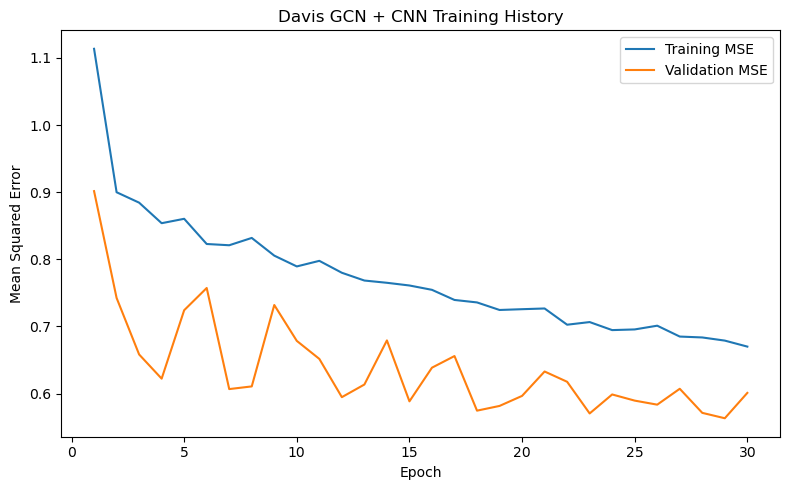

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_gcn_cnn_training_history.png


In [34]:
plt.figure(figsize=(8, 5))

plt.plot(
    gcn_history_df["epoch"],
    gcn_history_df["train_mse"],
    label="Training MSE",
)

plt.plot(
    gcn_history_df["epoch"],
    gcn_history_df["validation_mse"],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Davis GCN + CNN Training History")
plt.legend()
plt.tight_layout()

training_plot_path = (
    PLOTS_DIR
    / "davis_gcn_cnn_training_history.png"
)

plt.savefig(
    training_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(training_plot_path)

## True versus predicted affinity

Points close to the diagonal line represent more accurate predictions.

# Plot true versus predicted values

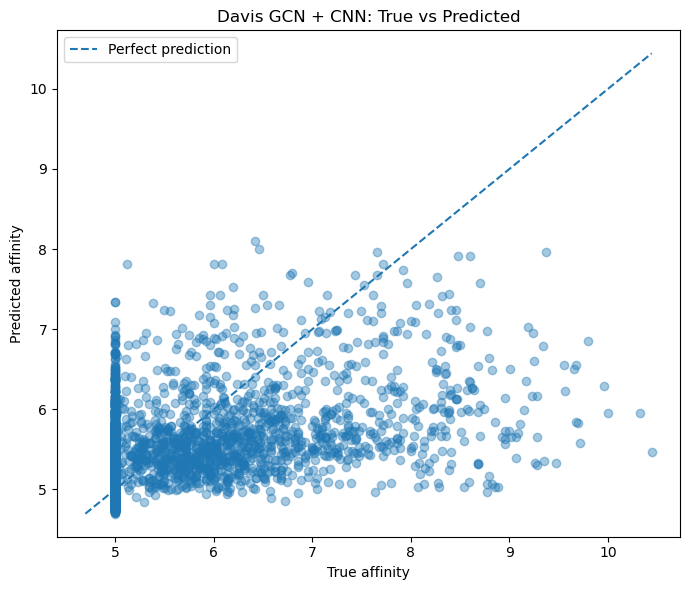

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_gcn_cnn_true_vs_predicted.png


In [35]:
plt.figure(figsize=(7, 6))

plt.scatter(
    true_values,
    predicted_values,
    alpha=0.4,
)

minimum_value = min(
    true_values.min(),
    predicted_values.min(),
)

maximum_value = max(
    true_values.max(),
    predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
    label="Perfect prediction",
)

plt.xlabel("True affinity")
plt.ylabel("Predicted affinity")
plt.title("Davis GCN + CNN: True vs Predicted")
plt.legend()
plt.tight_layout()

prediction_plot_path = (
    PLOTS_DIR
    / "davis_gcn_cnn_true_vs_predicted.png"
)

plt.savefig(
    prediction_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(prediction_plot_path)

# View the best predictions

In [36]:
best_predictions = gcn_predictions_df.sort_values(
    "absolute_error"
).head(10)

display(
    best_predictions[
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "absolute_error",
        ]
    ]
)

,drug_id,target_id,true_affinity,predicted_affinity,absolute_error
582,11656518,CDKL3,5.0,4.999974,0.000026
52,11717001,AKT3,5.0,4.999801,0.000199
883,3025986,PRKCI,5.0,5.000244,0.000244
2018,9929127,MAP3K1,5.0,4.999687,0.000313
3855,9929127,CDK4-cyclinD3,5.0,4.999600,0.000400
2110,10113978,ITK,5.0,4.999541,0.000459
2178,216239,PIK3CA(E542K),5.0,5.000493,0.000493
1758,216239,PIK3CA(M1043I),5.0,5.000493,0.000493
3606,216239,PIK3CA(H1047L),5.0,5.000493,0.000493
3986,216239,PIK3CA(C420R),5.0,5.000493,0.000493


# View the largest prediction errors

In [37]:
largest_errors = gcn_predictions_df.sort_values(
    "absolute_error",
    ascending=False,
).head(10)

display(
    largest_errors[
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "absolute_error",
        ]
    ]
)

,drug_id,target_id,true_affinity,predicted_affinity,absolute_error
2821,25127112,JAK2(JH1domain-catalytic),10.443698,5.462470,4.981228
1316,3062316,ABL1(E255K),10.327902,5.955604,4.372298
4406,156414,EGFR,9.721247,5.579226,4.142020
270,3062316,EPHB4,9.468521,5.333123,4.135398
275,3062316,ABL1(F317I),10.000000,5.955604,4.044396
1783,3062316,EPHB1,9.346787,5.352246,3.994541
4295,11314340,CLK4,9.275724,5.303184,3.972541
3057,11626560,MET(M1250T),9.259637,5.331422,3.928215
318,3062316,LCK,9.698970,5.826267,3.872703
1470,9884685,PIK3CA(C420R),8.886057,5.032310,3.853746


# Add the experiment to the log

In [38]:
append_experiment_log(
    dataset="davis",
    model_name="gcn",
    protein_encoder="cnn",
    split_type="random",
    seed=RANDOM_SEED,
    batch_size=BATCH_SIZE,
    epochs=len(gcn_history_df),
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    best_validation_mse=training_result[
        "best_validation_metrics"
    ]["mse"],
    test_metrics=gcn_test_metrics,
    model_path=gcn_checkpoint_path,
    model=gcn_model,
)

print("Experiment added to experiment_log.csv")

Experiment added to experiment_log.csv


# Confirm all outputs

In [39]:
required_outputs = [
    gcn_checkpoint_path,
    gcn_history_path,
    gcn_test_metrics_path,
    gcn_predictions_path,
    training_plot_path,
    prediction_plot_path,
]

for output_path in required_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in required_outputs
)

print("All Davis GCN + CNN outputs saved successfully.")

best_davis_gcn_cnn.pt → True
davis_gcn_cnn_training_history.csv → True
davis_gcn_cnn_test_metrics.json → True
davis_gcn_cnn_test_predictions.csv → True
davis_gcn_cnn_training_history.png → True
davis_gcn_cnn_true_vs_predicted.png → True
All Davis GCN + CNN outputs saved successfully.


# Davis GCN + CNN Baseline Complete

The baseline model has been:

- trained on the Davis random split;
- selected using validation MSE;
- evaluated on the unseen test set;
- saved as a model checkpoint;
- recorded in the experiment log;
- analysed using prediction plots and error tables.

The next notebook will compare GCN + CNN, GAT + CNN and GIN + CNN using the same Davis split.